In [1]:
import pandas as pd

orders = pd.read_csv("data/olist_orders_dataset.csv")
customers = pd.read_csv("data/olist_customers_dataset.csv")

orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
print(orders.shape, customers.shape)

(99441, 8) (99441, 5)


In [2]:
df = orders.merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")
print("합친 직후:", df.shape)

df = df[df["order_status"] == "delivered"]
print("배송 완료만:", df.shape)

합친 직후: (99441, 10)
배송 완료만: (96478, 10)


In [3]:
df = df.sort_values("order_purchase_timestamp")
df["order_number"] = df.groupby("customer_unique_id").cumcount() + 1
df[["customer_unique_id", "order_purchase_timestamp", "order_number"]].head(10)

,customer_unique_id,order_purchase_timestamp,order_number
30710,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09-15 12:16:38,1
93285,32ea3bdedab835c3aa6cb68ce66565ef,2016-10-03 09:44:50,1
28424,2f64e403852e6893ae37485d5fcacdaf,2016-10-03 16:56:50,1
97979,61db744d2f835035a5625b59350c6b63,2016-10-03 21:13:36,1
88472,8d3a54507421dbd2ce0a1d58046826e0,2016-10-03 22:06:03,1
6747,87776adb449c551e74c13fc34f036105,2016-10-03 22:31:31,1
62143,7390ed59fa1febbfda31a80b4318c8cb,2016-10-03 22:44:10,1
33504,10e89fd8e5c745f81bec101207ba4d7d,2016-10-03 22:51:30,1
78848,cd5a5843d35eebdf90368bf24d4a04cf,2016-10-04 09:06:10,1
64058,14359ea0c7a105749c0a56478825b015,2016-10-04 09:16:33,1


In [4]:
first = df[df["order_number"] == 1].copy()
order_count = df.groupby("customer_unique_id").size()
first["is_repeat"] = first["customer_unique_id"].map(order_count) >= 2

print("고객 수:", len(first))
print("재구매 고객 수:", first["is_repeat"].sum())
print("재구매 고객 비율:", round(first["is_repeat"].mean() * 100, 1), "%")

고객 수: 93358
재구매 고객 수: 2801
재구매 고객 비율: 3.0 %


In [5]:
first["order_delivered_customer_date"] = pd.to_datetime(first["order_delivered_customer_date"])
first["order_estimated_delivery_date"] = pd.to_datetime(first["order_estimated_delivery_date"])

first["delay_days"] = (first["order_delivered_customer_date"] - first["order_estimated_delivery_date"]).dt.days
first["is_late"] = first["delay_days"] > 0

first[["order_delivered_customer_date", "order_estimated_delivery_date", "delay_days", "is_late"]].head()

,order_delivered_customer_date,order_estimated_delivery_date,delay_days,is_late
30710,2016-11-09 07:47:38,2016-10-04,36.0,True
93285,2016-10-26 14:02:13,2016-10-27,-1.0,False
28424,2016-10-27 18:19:38,2016-11-07,-11.0,False
97979,2016-11-03 10:58:07,2016-11-29,-26.0,False
88472,2016-10-31 11:07:42,2016-11-23,-23.0,False


In [6]:
result = first.groupby("is_late")["is_repeat"].agg(["count", "mean"])
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["고객 수", "재구매율(%)"]
result

,고객 수,재구매율(%)
is_late,,
False,87002,3.0
True,6356,2.5


## 원인 후보 1: 첫 주문 배송 지연

### 가설
첫 주문 배송이 늦은 고객은 재구매를 덜 할 것이다

### 방법
- 고객 93,358명을 첫 주문이 예정일보다 늦게 도착했는지에 따라 두 그룹으로 나눔
- 각 그룹 안에서 다시 산 사람의 비율(재구매율)을 비교

### 결과
| 그룹 | 고객 수 | 다시 산 사람 | 재구매율 |
|---|---|---|---|
| 제때 받음 | 87,002명 | 약 2,642명 | 3.0% |
| 늦게 받음 | 6,356명 | 약 159명 | 2.5% |
| 합계 | 93,358명 | 2,801명 | 3.0% |

- 첫 주문을 늦게 받은 고객은 전체의 약 6.8%
- 재구매율은 각 그룹 안에서의 비율: 제때 받은 사람은 100명 중 3명, 늦게 받은 사람은 100명 중 2.5명이 다시 옴
- 두 그룹의 다시 산 사람을 더하면 전체 재구매 고객 2,801명과 일치

### 해석
- 방향은 가설과 같음: 늦게 받으면 조금 덜 돌아옴
- 하지만 차이는 0.5%p로 작음

### 다음 확인
- 이 차이가 통계적으로 의미 있는지
- 다른 요인(리뷰 점수, 결제 방식, 주문 금액)과 비교하면 어느 정도인지

In [7]:
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")

print("리뷰 줄 수:", len(reviews))
print("리뷰가 있는 주문 수:", reviews["order_id"].nunique())

리뷰 줄 수: 99224
리뷰가 있는 주문 수: 98673


In [8]:
review_score = reviews.groupby("order_id")["review_score"].mean()
first["review_score"] = first["order_id"].map(review_score)

print("첫 주문 고객 수:", len(first))
print("리뷰 점수가 없는 고객:", first["review_score"].isna().sum())
first["review_score"].value_counts().sort_index()

첫 주문 고객 수: 93358
리뷰 점수가 없는 고객: 616


review_score
1.0     9058
1.5        5
2.0     2830
2.5       16
3.0     7668
3.5       12
4.0    18353
4.5       31
5.0    54769
Name: count, dtype: int64

In [9]:
first["review_group"] = pd.cut(first["review_score"], bins=[0, 2.5, 3.5, 5], labels=["불만(1~2점)", "보통(3점)", "만족(4~5점)"])

result = first.groupby("review_group", observed=True)["is_repeat"].agg(["count", "mean"])
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["고객 수", "재구매율(%)"]
result

,고객 수,재구매율(%)
review_group,,
불만(1~2점),11909,2.8
보통(3점),7680,3.0
만족(4~5점),73153,3.0


## 원인 후보 2: 첫 주문 리뷰 점수

### 가설
첫 주문에 불만족한(리뷰 점수가 낮은) 고객은 재구매를 덜 할 것이다

### 방법
- 리뷰가 두 개 이상인 주문(551줄)이 있어서, 주문별 점수를 평균 내서 하나로 만든 뒤 붙임
- 리뷰가 없는 고객 616명은 비교에서 제외
- 점수를 불만(1~2점), 보통(3점), 만족(4~5점) 세 그룹으로 나눠 재구매율 비교

### 결과
| 그룹 | 고객 수 | 재구매율 |
|---|---|---|
| 불만(1~2점) | 11,909명 | 2.8% |
| 보통(3점) | 7,680명 | 3.0% |
| 만족(4~5점) | 73,153명 | 3.0% |

- 리뷰 점수 분포: 5점 59%, 1점 10%로 1점이 2점(3%)보다 많음

### 해석
- 가설과 달리 첫 주문 만족도에 따른 재구매율 차이가 거의 없음 (0.2%p)
- 배송 지연(0.5%p)과 함께 보면, 첫 주문 경험의 질은 재구매에 큰 영향을 주지 않음
- 재구매가 적은 이유는 다른 데 있을 가능성: 자주 살 필요가 없는 상품, 고객이 쇼핑몰을 기억하지 못함 등

### 다음 확인
- 상품 카테고리, 결제 방식, 주문 금액에 따른 재구매율

In [10]:
payments = pd.read_csv("data/olist_order_payments_dataset.csv")

pay_total = payments.groupby("order_id")["payment_value"].sum()
pay_installments = payments.groupby("order_id")["payment_installments"].max()
pay_type = payments.sort_values("payment_value").groupby("order_id")["payment_type"].last()

first["pay_total"] = first["order_id"].map(pay_total)
first["pay_installments"] = first["order_id"].map(pay_installments)
first["pay_type"] = first["order_id"].map(pay_type)

print("첫 주문 고객 수:", len(first))
first[["pay_total", "pay_installments", "pay_type"]].head()

첫 주문 고객 수: 93358


,pay_total,pay_installments,pay_type
30710,NaN,NaN,NaN
93285,45.46,1.0,boleto
28424,39.09,1.0,boleto
97979,53.73,1.0,boleto
88472,133.46,6.0,credit_card


In [11]:
result = first.groupby("pay_type")["is_repeat"].agg(["count", "mean"])
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["고객 수", "재구매율(%)"]
result.sort_values("고객 수", ascending=False)

,고객 수,재구매율(%)
pay_type,,
credit_card,70457,3.0
boleto,18625,3.0
voucher,2835,3.6
debit_card,1440,2.3


In [12]:
first["inst_group"] = pd.cut(first["pay_installments"], bins=[0, 1, 3, 6, 24], labels=["일시불", "2~3개월", "4~6개월", "7개월 이상"])

result = first.groupby("inst_group", observed=True)["is_repeat"].agg(["count", "mean"])
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["고객 수", "재구매율(%)"]
result

,고객 수,재구매율(%)
inst_group,,
일시불,45405,2.7
2~3개월,21508,2.8
4~6개월,15178,3.2
7개월 이상,11264,4.0


In [13]:
card = first[first["pay_type"] == "credit_card"].copy()
card["amount_group"] = pd.qcut(card["pay_total"], q=3, labels=["저가", "중가", "고가"])

table = card.pivot_table(index="amount_group", columns="inst_group", values="is_repeat", aggfunc="mean", observed=True)
(table * 100).round(1)

inst_group,일시불,2~3개월,4~6개월,7개월 이상
amount_group,,,,
저가,2.4,3.7,4.9,6.7
중가,2.6,2.4,2.9,5.6
고가,2.4,2.4,2.4,3.2


In [14]:
count_table = card.pivot_table(index="amount_group", columns="inst_group", values="is_repeat", aggfunc="count", observed=True)
count_table

inst_group,일시불,2~3개월,4~6개월,7개월 이상
amount_group,,,,
저가,12383,6945,3787,372
중가,7115,7921,5158,3288
고가,3193,6507,6194,7592


## 원인 후보 3: 첫 주문 결제 방식과 할부

### 결제 정리 방법
- 한 주문에 결제가 여러 줄일 수 있어서 주문별로 하나로 정리
  - 결제 총액: 같은 주문의 결제 금액 합계
  - 할부 개월 수: 그 주문에서 가장 긴 할부
  - 주 결제 수단: 금액이 가장 큰 결제의 수단
- 결제 기록이 없는 주문 1건(데이터의 첫 주문)은 제외

### 결과 1: 결제 수단별 재구매율
| 결제 수단 | 고객 수 | 재구매율 |
|---|---|---|
| 신용카드 | 70,457명 | 3.0% |
| 은행 전표(boleto) | 18,625명 | 3.0% |
| 바우처 | 2,835명 | 3.6% |
| 체크카드 | 1,440명 | 2.3% |

- 신용카드와 은행 전표는 차이 없음
- 바우처와 체크카드는 그룹이 작아서 통계 검정 필요

### 결과 2: 할부 개월 수별 재구매율
| 할부 | 고객 수 | 재구매율 |
|---|---|---|
| 일시불 | 45,405명 | 2.7% |
| 2-3개월 | 21,508명 | 2.8% |
| 4-6개월 | 15,178명 | 3.2% |
| 7개월 이상 | 11,264명 | 4.0% |

- 할부가 길수록 재구매율이 계단처럼 증가, 7개월 이상은 일시불의 약 1.5배
- 지금까지 본 원인 후보 중 가장 큰 차이

### 결과 3: 금액이 진짜 원인인지 확인 (신용카드 고객만)
할부를 길게 쓰는 건 비싼 물건을 살 때라서, 금액이 진짜 원인일 수 있음 (교란 변수)
→ 결제 금액을 저가·중가·고가로 나눠서 같은 금액끼리 비교

| 금액 \ 할부 | 일시불 | 2-3개월 | 4-6개월 | 7개월 이상 |
|---|---|---|---|---|
| 저가 | 2.4% | 3.7% | 4.9% | 6.7% (372명) |
| 중가 | 2.6% | 2.4% | 2.9% | 5.6% (3,288명) |
| 고가 | 2.4% | 2.4% | 2.4% | 3.2% (7,592명) |

- 일시불끼리는 금액이 달라도 재구매율이 같음 (2.4-2.6%) → 금액은 원인이 아님
- 같은 금액 안에서도 할부가 길수록 재구매율이 높음 → 할부 습관이 재구매와 관련
- 저가 물건을 7개월 넘게 할부하는 고객이 6.7%로 가장 높음 (단, 372명으로 작은 그룹)

### 해석
- 비싸서 할부를 쓴 게 아니라, 할부를 습관적으로 쓰는 소비가 활발한 고객이 다시 올 가능성이 높음
- 활용 방안: 무이자 할부 혜택으로 이런 고객을 붙잡는 마케팅

### 다음 확인
- 7개월 이상 할부 효과가 통계적으로 의미 있는지
- 상관관계일 뿐 인과관계는 아님 (할부를 늘린다고 재구매가 늘어난다고 단정할 수 없음)

In [15]:
items = pd.read_csv("data/olist_order_items_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")
trans = pd.read_csv("data/product_category_name_translation.csv")

items1 = items[items["order_item_id"] == 1]
cat = items1.merge(products[["product_id", "product_category_name"]], on="product_id")
cat = cat.merge(trans, on="product_category_name", how="left")

order_cat = cat.set_index("order_id")["product_category_name_english"]
first["category"] = first["order_id"].map(order_cat)

print("첫 주문 고객 수:", len(first))
print("카테고리가 없는 고객:", first["category"].isna().sum())
print("카테고리 종류:", first["category"].nunique())

첫 주문 고객 수: 93358
카테고리가 없는 고객: 1336
카테고리 종류: 71


In [16]:
result = first.groupby("category")["is_repeat"].agg(["count", "mean"])
result = result[result["count"] >= 1000]
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["고객 수", "재구매율(%)"]
result.sort_values("재구매율(%)", ascending=False)

,고객 수,재구매율(%)
category,,
fashion_bags_accessories,1691,5.7
furniture_decor,5927,4.5
bed_bath_table,8732,4.4
sports_leisure,7203,3.9
garden_tools,3332,3.0
pet_shop,1630,3.0
computers_accessories,6286,2.9
perfumery,2988,2.8
health_beauty,8353,2.7


## 원인 후보 4: 첫 주문 상품 카테고리

### 가설
자주 사는 물건(생활용품, 화장품)을 처음 산 고객은 더 오고, 가끔 사는 물건(가구, 가전)을 산 고객은 덜 올 것이다

### 방법
- 주문 → 주문 상품 → 상품 → 카테고리 번역, 세 번 합쳐서 카테고리를 구함
- 한 주문에 상품이 여러 개일 수 있어서 첫 번째로 담은 상품(order_item_id = 1)의 카테고리를 사용
- 고객이 1,000명 이상인 카테고리만 비교 (작은 그룹은 비율이 쉽게 흔들림)

### 결과
| 카테고리 | 고객 수 | 재구매율 |
|---|---|---|
| 가방·패션잡화 | 1,691명 | 5.7% |
| 가구·인테리어 | 5,927명 | 4.5% |
| 침구·욕실·식탁 | 8,732명 | 4.4% |
| 스포츠·레저 | 7,203명 | 3.9% |
| 건강·미용 | 8,353명 | 2.7% |
| 시계·선물 | 5,315명 | 2.1% |
| 자동차용품 | 3,704명 | 2.0% |
| 재밌는 잡화(선물용) | 3,473명 | 1.9% |
| 전자기기 | 2,463명 | 1.6% |

- 가장 높은 카테고리와 낮은 카테고리의 차이 4.1%p (약 3.5배), 지금까지 원인 후보 중 가장 큼

### 해석
- 가설은 반만 맞음: 가구·인테리어는 예상과 달리 높고, 건강·미용은 평균 수준
- 위쪽은 집 꾸미기·생활 관련 상품: 한 번 사면 관련 상품을 이어서 사게 됨
- 아래쪽은 선물이나 한 번 사면 오래 쓰는 상품: 재구매할 이유가 적음
- "자주 쓰는 물건인지"보다 "관련 상품을 이어서 사게 되는지"가 중요해 보임

### 다음 확인
- 재구매한 고객이 두 번째에 같은 카테고리를 샀는지, 다른 카테고리를 샀는지
- 카테고리 차이가 통계적으로 의미 있는지

In [17]:
second = df[df["order_number"] == 2][["customer_unique_id", "order_id"]].copy()
second["category_2"] = second["order_id"].map(order_cat)

pair = first[["customer_unique_id", "category"]].merge(second[["customer_unique_id", "category_2"]], on="customer_unique_id")
pair = pair.dropna()
pair["same"] = pair["category"] == pair["category_2"]

print("비교한 재구매 고객 수:", len(pair))
print("두 번째도 같은 카테고리를 산 비율:", round(pair["same"].mean() * 100, 1), "%")

비교한 재구매 고객 수: 2734
두 번째도 같은 카테고리를 산 비율: 47.0 %


In [18]:
result = pair.groupby("category")["same"].agg(["count", "mean"])
result = result[result["count"] >= 50]
result["mean"] = (result["mean"] * 100).round(1)
result.columns = ["재구매 고객 수", "같은 카테고리 비율(%)"]
result.sort_values("같은 카테고리 비율(%)", ascending=False)

,재구매 고객 수,같은 카테고리 비율(%)
category,,
home_appliances,58,82.8
computers_accessories,178,65.7
health_beauty,223,61.9
sports_leisure,276,58.0
bed_bath_table,380,57.9
watches_gifts,111,53.2
auto,74,51.4
fashion_bags_accessories,95,48.4
telephony,96,43.8


In [19]:
second_time = df[df["order_number"] == 2].set_index("customer_unique_id")["order_purchase_timestamp"]
first["second_time"] = first["customer_unique_id"].map(second_time)
first["days_to_second"] = (first["second_time"] - first["order_purchase_timestamp"]).dt.days

rep = first[first["is_repeat"]]
print("재구매 고객 수:", len(rep))
print("같은 날 두 번째 주문:", (rep["days_to_second"] == 0).sum(), "명")
print("같은 날 비율:", round((rep["days_to_second"] == 0).mean() * 100, 1), "%")
rep["days_to_second"].describe()

재구매 고객 수: 2801
같은 날 두 번째 주문: 853 명
같은 날 비율: 30.5 %


count    2801.000000
mean       80.844698
std       109.899443
min         0.000000
25%         0.000000
50%        28.000000
75%       126.000000
max       608.000000
Name: days_to_second, dtype: float64

In [20]:
first["is_repeat2"] = first["days_to_second"] >= 1

print("기존 재구매 고객:", first["is_repeat"].sum(), "명,", round(first["is_repeat"].mean() * 100, 2), "%")
print("새 정의 재구매 고객:", first["is_repeat2"].sum(), "명,", round(first["is_repeat2"].mean() * 100, 2), "%")

기존 재구매 고객: 2801 명, 3.0 %
새 정의 재구매 고객: 1948 명, 2.09 %


In [21]:
def compare(col, min_count=0):
    r = first.groupby(col, observed=True)[["is_repeat", "is_repeat2"]].mean() * 100
    r["고객 수"] = first.groupby(col, observed=True).size()
    r = r[r["고객 수"] >= min_count].round(1)
    r.columns = ["기존 재구매율(%)", "새 재구매율(%)", "고객 수"]
    return r

print(compare("is_late"), "\n")
print(compare("review_group"), "\n")
print(compare("pay_type"), "\n")
print(compare("inst_group"))

         기존 재구매율(%)  새 재구매율(%)   고객 수
is_late                              
False           3.0        2.1  87002
True            2.5        1.5   6356 

              기존 재구매율(%)  새 재구매율(%)   고객 수
review_group                              
불만(1~2점)             2.8        1.7  11909
보통(3점)               3.0        1.9   7680
만족(4~5점)             3.0        2.2  73153 

             기존 재구매율(%)  새 재구매율(%)   고객 수
pay_type                                 
boleto              3.0        2.1  18625
credit_card         3.0        2.1  70457
debit_card          2.3        1.5   1440
voucher             3.6        2.7   2835 

            기존 재구매율(%)  새 재구매율(%)   고객 수
inst_group                              
일시불                2.7        2.0  45405
2~3개월              2.8        1.9  21508
4~6개월              3.2        2.2  15178
7개월 이상             4.0        2.7  11264


In [22]:
print(compare("category", min_count=1000).sort_values("새 재구매율(%)", ascending=False))

                          기존 재구매율(%)  새 재구매율(%)  고객 수
category                                             
fashion_bags_accessories         5.7        3.6  1691
furniture_decor                  4.5        2.7  5927
sports_leisure                   3.9        2.7  7203
bed_bath_table                   4.4        2.6  8732
pet_shop                         3.0        2.5  1630
garden_tools                     3.0        2.4  3332
perfumery                        2.8        2.4  2988
telephony                        2.4        2.1  3990
housewares                       2.7        2.1  5505
toys                             2.4        2.0  3672
health_beauty                    2.7        1.9  8353
computers_accessories            2.9        1.7  6286
watches_gifts                    2.1        1.7  5315
baby                             2.3        1.6  2693
auto                             2.0        1.6  3704
stationery                       2.1        1.6  2197
cool_stuff                  

In [23]:
card = first[first["pay_type"] == "credit_card"].copy()
card["amount_group"] = pd.qcut(card["pay_total"], q=3, labels=["저가", "중가", "고가"])
table = card.pivot_table(index="amount_group", columns="inst_group", values="is_repeat2", aggfunc="mean", observed=True)
(table * 100).round(1)

inst_group,일시불,2~3개월,4~6개월,7개월 이상
amount_group,,,,
저가,1.8,2.5,2.8,4.0
중가,2.0,1.5,2.0,3.1
고가,1.9,1.9,1.9,2.4


## 재구매 정의 다시 정하기

### 발견
- 재구매 고객 2,801명 중 853명(30.5%)이 첫 주문과 같은 날 두 번째 주문을 함
- 첫 주문과 두 번째 주문 사이 기간: 하위 25%가 0일, 중앙값 28일, 평균 약 81일
- 같은 날 주문은 다시 온 것이 아니라 한 번에 살 것을 나눠 주문한 경우로 판단

### 새 정의
- 진짜 재구매 = 첫 주문과 다른 날(1일 이상 지나서) 두 번째 주문을 한 경우
- 재구매 고객 2,801명(3.0%) → 1,948명(2.09%)

### 새 정의로 다시 본 결과
| 원인 후보 | 기존 정의 | 새 정의 | 변화 |
|---|---|---|---|
| 배송 지연 | 제때 3.0% / 늦음 2.5% | 제때 2.1% / 늦음 1.5% | 결론 유지, 더 뚜렷해짐 |
| 리뷰 점수 | 불만 2.8% / 보통 3.0% / 만족 3.0% | 불만 1.7% / 보통 1.9% / 만족 2.2% | 차이 없음 → 만족할수록 높음 |
| 결제 수단 | 바우처 3.6%로 가장 높음 | 바우처 2.7%로 가장 높음 | 결론 유지 |
| 할부 | 일시불 2.7% → 7개월 이상 4.0% | 일시불 2.0% → 7개월 이상 2.7% | 효과 약해짐, 7개월 이상만 확실히 높음 |
| 카테고리 | 1.6% ~ 5.7% | 1.4% ~ 3.6% | 순위 대부분 유지, 여전히 가장 큰 요인 |

- 할부×금액 표: 일시불끼리는 금액과 상관없이 1.8-2.0%로 비슷, 7개월 이상은 모든 금액 구간에서 가장 높음

### 교훈
- 재구매를 어떻게 정의하느냐에 따라 결론이 바뀜
- 기존 정의 그대로였다면 "만족도는 재구매와 상관없다"는 틀린 결론을 냈을 것

In [24]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\LG\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [25]:
from scipy.stats import chi2_contingency

def test(col, min_count=0):
    data = first.dropna(subset=[col])
    counts = data[col].value_counts()
    data = data[data[col].isin(counts[counts >= min_count].index)]
    table = pd.crosstab(data[col], data["is_repeat2"])
    chi2, p, dof, expected = chi2_contingency(table)
    return p

for col, m in [("is_late", 0), ("review_group", 0), ("pay_type", 0), ("inst_group", 0), ("category", 1000)]:
    p = test(col, m)
    print(f"{col:15s} p-value = {p:.2e}   {'의미 있음' if p < 0.05 else '우연일 수 있음'}")

is_late         p-value = 1.92e-03   의미 있음
review_group    p-value = 3.31e-04   의미 있음
pay_type        p-value = 6.52e-02   우연일 수 있음
inst_group      p-value = 5.74e-05   의미 있음
category        p-value = 4.16e-12   의미 있음


## 통계 검정: 차이가 우연인지 확인

### 방법
- 카이제곱 검정: 그룹과 재구매 여부(새 정의)가 서로 관련이 있는지 확인
- p-value가 0.05보다 작으면 우연으로 보기 어렵다고 판단
- 카테고리는 고객 1,000명 이상인 카테고리만 검정

### 결과
| 원인 후보 | p-value | 판단 |
|---|---|---|
| 배송 지연 | 0.0019 | 의미 있음 |
| 리뷰 점수 | 0.00033 | 의미 있음 |
| 결제 수단 | 0.065 | 우연일 수 있음 |
| 할부 | 0.000057 | 의미 있음 |
| 카테고리 | 4.2e-12 | 매우 강하게 의미 있음 |

### 해석
- 결제 수단(바우처가 높아 보였던 것)은 통계적으로 확인되지 않아 결론에서 제외
- 카테고리는 차이의 크기와 통계 모두에서 가장 강한 요인
- 카이제곱 검정은 그룹 사이 어딘가에 차이가 있다는 것만 알려줌. 어느 그룹이 높은지는 앞의 표로 판단
- 고객 수가 9만 명 이상이라 작은 차이도 의미 있게 나올 수 있으므로, 차이의 크기도 함께 봐야 함

### 최종 순위
1. 상품 카테고리: 1.4% ~ 3.6%
2. 장기 할부: 일시불 2.0% vs 7개월 이상 2.7%
3. 배송 지연: 늦음 1.5% vs 제때 2.1%
4. 리뷰 점수: 불만 1.7% vs 만족 2.2%

In [26]:
import matplotlib.pyplot as plt
import os

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("figures", exist_ok=True)
print("준비 완료")

준비 완료


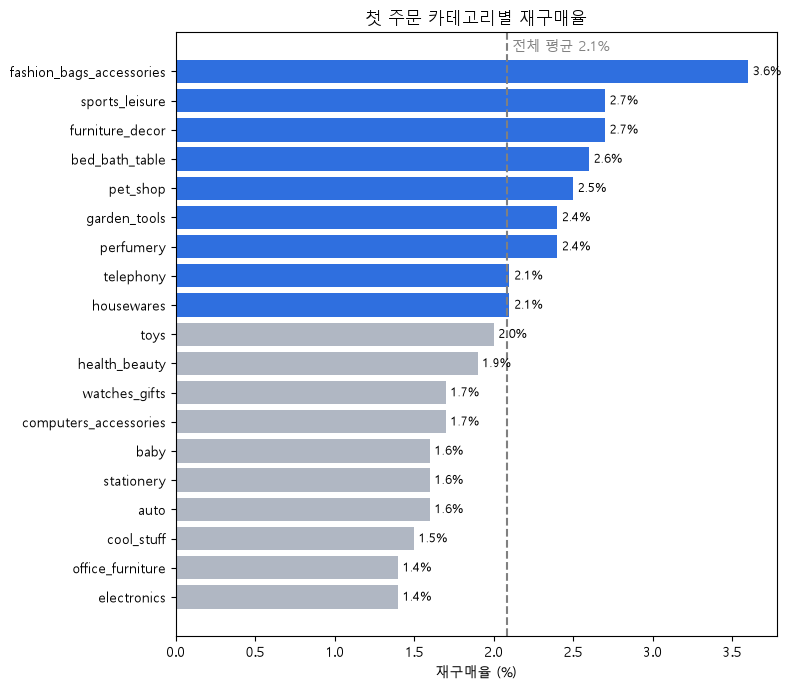

In [27]:
cat = compare("category", min_count=1000).sort_values("새 재구매율(%)")
avg = first["is_repeat2"].mean() * 100
colors = ["#2f6fdf" if v >= avg else "#b0b7c3" for v in cat["새 재구매율(%)"]]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(cat.index, cat["새 재구매율(%)"], color=colors)
ax.axvline(avg, color="gray", linestyle="--")
ax.text(avg, len(cat) - 0.3, f" 전체 평균 {avg:.1f}%", color="gray")

for i, v in enumerate(cat["새 재구매율(%)"]):
    ax.text(v + 0.03, i, f"{v}%", va="center", fontsize=9)

ax.set_xlabel("재구매율 (%)")
ax.set_title("첫 주문 카테고리별 재구매율")
plt.tight_layout()
plt.savefig("figures/category_repeat.png", dpi=150)
plt.show()

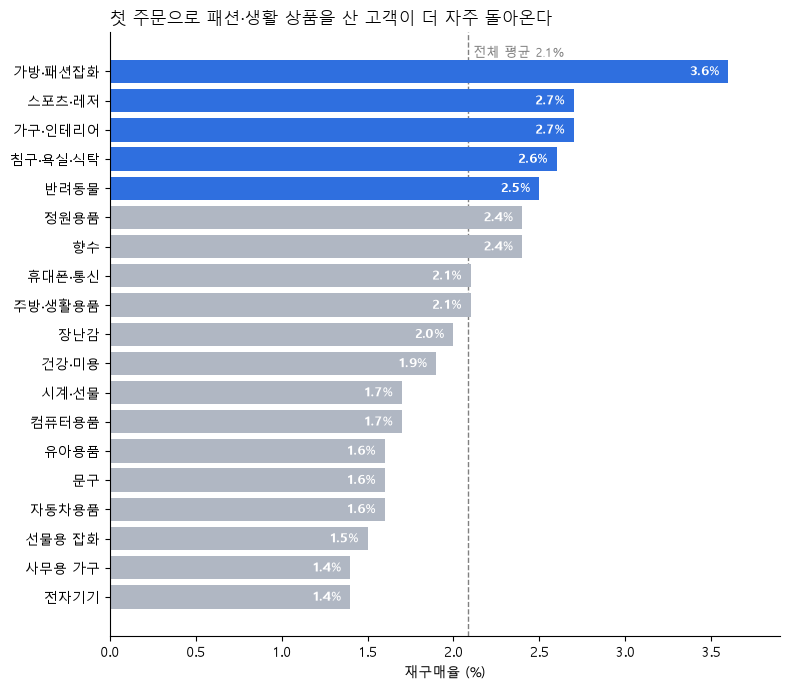

In [28]:
names = {
    "fashion_bags_accessories": "가방·패션잡화", "sports_leisure": "스포츠·레저",
    "furniture_decor": "가구·인테리어", "bed_bath_table": "침구·욕실·식탁",
    "pet_shop": "반려동물", "garden_tools": "정원용품", "perfumery": "향수",
    "telephony": "휴대폰·통신", "housewares": "주방·생활용품", "toys": "장난감",
    "health_beauty": "건강·미용", "watches_gifts": "시계·선물",
    "computers_accessories": "컴퓨터용품", "baby": "유아용품", "stationery": "문구",
    "auto": "자동차용품", "cool_stuff": "선물용 잡화", "office_furniture": "사무용 가구",
    "electronics": "전자기기",
}
cat = compare("category", min_count=1000).sort_values("새 재구매율(%)")
labels = [names.get(c, c) for c in cat.index]
values = cat["새 재구매율(%)"]
avg = first["is_repeat2"].mean() * 100
colors = ["#2f6fdf" if v >= 2.5 else "#b0b7c3" for v in values]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(labels, values, color=colors)
ax.axvline(avg, color="gray", linestyle="--", linewidth=1, zorder=0)
ax.text(avg + 0.03, len(cat) - 0.5, f"전체 평균 {avg:.1f}%", color="gray", fontsize=9)

for i, v in enumerate(values):
    ax.text(v - 0.05, i, f"{v}%", va="center", ha="right", color="white", fontsize=9, fontweight="bold")

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_xlim(0, values.max() + 0.3)
ax.set_xlabel("재구매율 (%)")
ax.set_title("첫 주문으로 패션·생활 상품을 산 고객이 더 자주 돌아온다", fontsize=12, loc="left")
plt.tight_layout()
plt.savefig("figures/category_repeat.png", dpi=150)
plt.show()

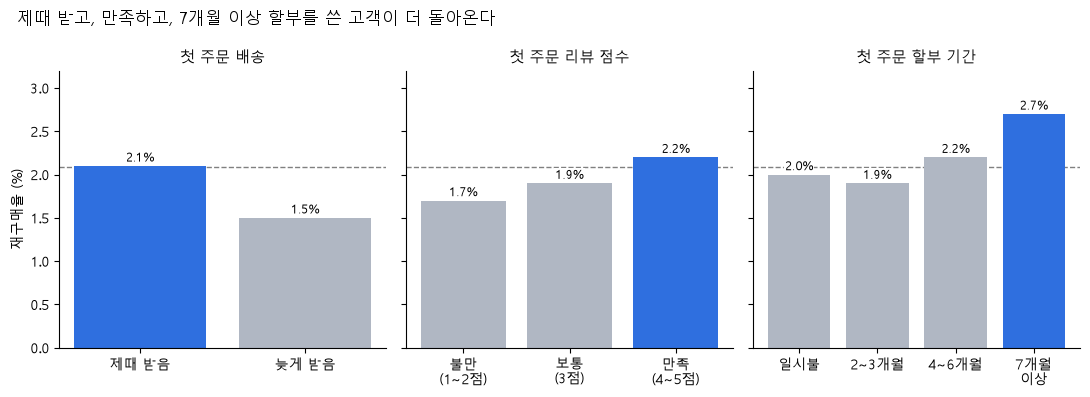

In [29]:
late = compare("is_late")["새 재구매율(%)"]
late.index = ["제때 받음", "늦게 받음"]

review = compare("review_group")["새 재구매율(%)"]
review.index = ["불만\n(1~2점)", "보통\n(3점)", "만족\n(4~5점)"]

inst = compare("inst_group")["새 재구매율(%)"]
inst.index = ["일시불", "2~3개월", "4~6개월", "7개월\n이상"]

panels = [("첫 주문 배송", late), ("첫 주문 리뷰 점수", review), ("첫 주문 할부 기간", inst)]

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for ax, (title, s) in zip(axes, panels):
    colors = ["#2f6fdf" if v == s.max() else "#b0b7c3" for v in s]
    ax.bar(s.index, s.values, color=colors)
    ax.axhline(avg, color="gray", linestyle="--", linewidth=1, zorder=0)
    for i, v in enumerate(s):
        ax.text(i, v + 0.05, f"{v}%", ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_title(title, fontsize=11)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("재구매율 (%)")
axes[0].set_ylim(0, 3.2)
fig.suptitle("제때 받고, 만족하고, 7개월 이상 할부를 쓴 고객이 더 돌아온다", x=0.02, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig("figures/factors_repeat.png", dpi=150)
plt.show()

In [30]:
        ax.text(i, v + 0.05, f"{v}%", ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))

Text(3, 2.75, '2.7%')

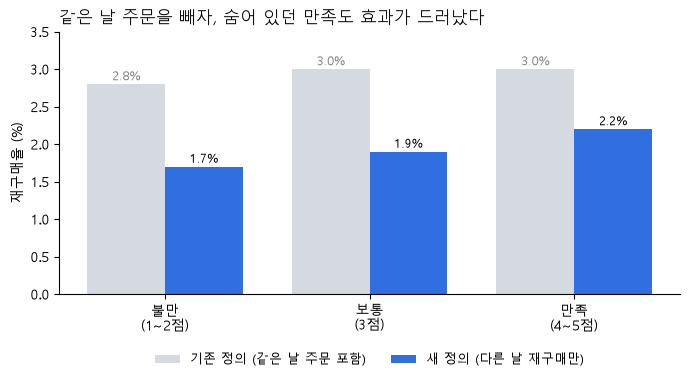

In [31]:
rv = compare("review_group")[["기존 재구매율(%)", "새 재구매율(%)"]]
rv.index = ["불만\n(1~2점)", "보통\n(3점)", "만족\n(4~5점)"]

x = range(len(rv))
w = 0.38

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - w / 2 for i in x], rv["기존 재구매율(%)"], w, color="#d5d9e0", label="기존 정의 (같은 날 주문 포함)")
ax.bar([i + w / 2 for i in x], rv["새 재구매율(%)"], w, color="#2f6fdf", label="새 정의 (다른 날 재구매만)")

for i in x:
    ax.text(i - w / 2, rv["기존 재구매율(%)"].iloc[i] + 0.05, f"{rv['기존 재구매율(%)'].iloc[i]}%", ha="center", fontsize=9, color="gray")
    ax.text(i + w / 2, rv["새 재구매율(%)"].iloc[i] + 0.05, f"{rv['새 재구매율(%)'].iloc[i]}%", ha="center", fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(rv.index)
ax.set_ylim(0, 3.5)
ax.set_ylabel("재구매율 (%)")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("같은 날 주문을 빼자, 숨어 있던 만족도 효과가 드러났다", fontsize=12, loc="left")
plt.tight_layout()
plt.savefig("figures/definition_change.png", dpi=150)
plt.show()

## 결론과 제안

### 핵심 결론
1. 첫 주문 카테고리가 재구매와 가장 강하게 관련됨: 패션·스포츠·인테리어·침구 2.5-3.6%, 전자기기·선물용 잡화 1.4-1.5%
2. 7개월 이상 장기 할부 고객은 금액과 상관없이 재구매율이 높음 (일시불 2.0% vs 2.7%)
3. 첫 주문 배송이 늦으면 재구매율이 약 30% 낮아짐 (2.1% vs 1.5%)
4. 첫 주문에 만족한 고객일수록 재구매율이 높음 (불만 1.7% vs 만족 2.2%)

### 제안
- 패션·인테리어·침구 첫 구매 고객에게 관련 상품 추천 (재구매 고객의 절반은 다른 카테고리를 구매)
- 장기 할부 고객에게 다음 구매 무이자 할부 혜택 (카드사 제휴)
- 첫 주문 배송 예정일 준수 관리
- 첫 주문 리뷰 점수가 낮은 고객에게 사과 쿠폰 (바우처 효과는 통계적으로 확인되지 않아 실험으로 검증 필요)

### 한계
- 관계를 찾은 것이지 원인을 증명한 것은 아님. 효과를 확인하려면 A/B 테스트 필요
- 재구매율 자체가 2% 수준으로 매우 낮아, 어떤 요인으로도 대부분의 고객은 돌아오지 않음
- 데이터 기간이 짧아 늦게 첫 주문한 고객은 다시 올 시간이 부족했음
- 재구매 기준(다른 날 두 번째 주문)에 따라 숫자가 달라질 수 있음